# Week 3 Lab: LoRA, Quantization Reasoning, PEFT Planning, and QA Evaluation

This notebook is the CPU-friendly core route for Week 3 of **Deep Learning in 100 Hours**. It explains and tests the mechanisms without downloading a pretrained model. LoRA and QLoRA ideas are attributed to their original papers in **references/SOURCES.md**; the local code is a teaching implementation.

| Day | Main idea | Evidence to keep |
|---|---|---|
| 11 | LoRA mechanism, gradients, merging | Frozen base and equivalent merged output |
| 12 | Quantization error and memory ledger | Error-by-bit table and honest memory estimate |
| 13 | Hugging Face/PEFT preflight | Module inventory and configuration manifest |
| 14 | QA normalization, EM, token F1 | Metric examples, strata, and leakage check |
| 15 | Controlled rank comparison | Separate train/validation results for ranks 2 and 8 |

**Core Light:** every code cell in this notebook. **Optional Heavy:** downloading a Hugging Face model, bitsandbytes 4-bit loading, and multi-seed language-model fine-tuning. Optional work is never triggered automatically.

In [1]:
from collections import Counter
import importlib.util
import json
import time

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

from dl100h.data import CharTokenizer
from dl100h.lora import LoRALinear
from dl100h.pathvqa import TOY_PATHVQA, exact_match, normalize_answer, token_f1
from dl100h.tiny_gpt import GPTConfig, TinyGPT
from dl100h.utils import count_parameters, seed_everything

seed_everything(42)
device = torch.device('cpu')
print({'torch': torch.__version__, 'device': str(device)})

{'torch': '2.5.1', 'device': 'cpu'}


# Day 11 — LoRA: a frozen base plus a low-rank update

For a frozen linear weight $W_0\in\mathbb{R}^{d_{out}\times d_{in}}$, LoRA learns

$$\Delta W = \frac{\alpha}{r}BA,$$

where $A\in\mathbb{R}^{r\times d_{in}}$ and $B\in\mathbb{R}^{d_{out}\times r}$. The trainable parameter count is $r(d_{in}+d_{out})$, instead of $d_{in}d_{out}$ for a full weight update.

This implementation initializes $B=0$, so the adapter initially produces exactly the frozen base output. A useful consequence is that $A$ receives zero gradient on the first backward pass; after $B$ changes, both factors can receive gradients.

In [2]:
seed_everything(11)
base_layer = nn.Linear(16, 12)
lora_layer = LoRALinear(base_layer, rank=2, alpha=4, dropout=0.0)
lora_input = torch.randn(8, 16)

with torch.inference_mode():
    base_output = base_layer(lora_input)
    initial_lora_output = lora_layer(lora_input)

torch.testing.assert_close(initial_lora_output, base_output)
assert not any(parameter.requires_grad for parameter in lora_layer.base.parameters())
expected_trainable = 2 * (16 + 12)
assert count_parameters(lora_layer, trainable_only=True) == expected_trainable
{
    'total_parameters': count_parameters(lora_layer),
    'trainable_parameters': count_parameters(lora_layer, trainable_only=True),
    'initial_maximum_difference': (initial_lora_output - base_output).abs().max().item(),
}

{'total_parameters': 260,
 'trainable_parameters': 56,
 'initial_maximum_difference': 0.0}

In [3]:
gradient_target = torch.randn(8, 12)
lora_optimizer = torch.optim.SGD(
    [parameter for parameter in lora_layer.parameters() if parameter.requires_grad], lr=0.1
)

first_loss = F.mse_loss(lora_layer(lora_input), gradient_target)
first_loss.backward()
assert lora_layer.base.weight.grad is None
assert torch.count_nonzero(lora_layer.lora_a.grad) == 0
assert lora_layer.lora_b.grad.norm() > 0
first_a_gradient_norm = lora_layer.lora_a.grad.norm().item()
first_b_gradient_norm = lora_layer.lora_b.grad.norm().item()
lora_optimizer.step()

lora_optimizer.zero_grad(set_to_none=True)
second_loss = F.mse_loss(lora_layer(lora_input), gradient_target)
second_loss.backward()
assert lora_layer.lora_a.grad.norm() > 0
{
    'first_A_gradient_norm': first_a_gradient_norm,
    'first_B_gradient_norm': first_b_gradient_norm,
    'second_A_gradient_norm': lora_layer.lora_a.grad.norm().item(),
    'base_gradient': lora_layer.base.weight.grad,
}

{'first_A_gradient_norm': 0.0,
 'first_B_gradient_norm': 0.5066571831703186,
 'second_A_gradient_norm': 0.04941337928175926,
 'base_gradient': None}

In [4]:
lora_layer.eval()
merged_layer = lora_layer.merged_linear().eval()
with torch.inference_mode():
    adapter_prediction = lora_layer(lora_input)
    merged_prediction = merged_layer(lora_input)

torch.testing.assert_close(adapter_prediction, merged_prediction, rtol=1e-5, atol=1e-6)
{
    'adapter_parameters_at_training_time': count_parameters(lora_layer),
    'merged_parameters_at_inference': count_parameters(merged_layer),
    'maximum_merge_error': (adapter_prediction - merged_prediction).abs().max().item(),
}

{'adapter_parameters_at_training_time': 260,
 'merged_parameters_at_inference': 204,
 'maximum_merge_error': 2.384185791015625e-07}

## Day 11 practice and acceptance

1. Derive the trainable parameter formula and verify it for three ranks.
2. Change $\alpha$ while keeping rank fixed and measure the initial update after one optimizer step.
3. Add adapter dropout and explain why merge equivalence must be tested in eval mode.
4. Inspect Tiny GPT module names and argue which projections should receive adapters.

**Accept the day when:** the base is frozen, the zero-$B$ gradient behavior is explained, trainable counts are correct, and merging preserves outputs.

# Day 12 — Quantization reasoning and the QLoRA memory ledger

Quantization stores or represents values with fewer levels. The uniform symmetric example below demonstrates reconstruction error only. It is **not NF4** and it is **not QLoRA training**.

QLoRA keeps a quantized pretrained base frozen and learns LoRA adapters through that base. Its practical memory story also involves quantization metadata, adapter parameters, gradients, optimizer states, activations, temporary tensors, and framework overhead. A weight-only calculation is therefore a floor, not a promise.

In [5]:
def symmetric_fake_quantize(tensor: torch.Tensor, bits: int) -> torch.Tensor:
    if bits < 2:
        raise ValueError('bits must be at least 2')
    maximum_integer = 2 ** (bits - 1) - 1
    scale = tensor.abs().max().clamp_min(1e-8) / maximum_integer
    integer_values = (tensor / scale).round().clamp(-maximum_integer, maximum_integer)
    return integer_values * scale

torch.manual_seed(12)
full_precision_weights = torch.randn(4096)
quantization_results = []
for bits in (8, 4, 2):
    reconstructed = symmetric_fake_quantize(full_precision_weights, bits)
    mse = F.mse_loss(reconstructed, full_precision_weights).item()
    maximum_error = (reconstructed - full_precision_weights).abs().max().item()
    quantization_results.append({'bits': bits, 'mse': mse, 'maximum_error': maximum_error})

assert quantization_results[0]['mse'] < quantization_results[1]['mse'] < quantization_results[2]['mse']
quantization_results

[{'bits': 8,
  'mse': 8.057062223087996e-05,
  'maximum_error': 0.015555918216705322},
 {'bits': 4,
  'mse': 0.026541324332356453,
  'maximum_error': 0.28230470418930054},
 {'bits': 2, 'mse': 0.8377827405929565, 'maximum_error': 1.975021243095398}]

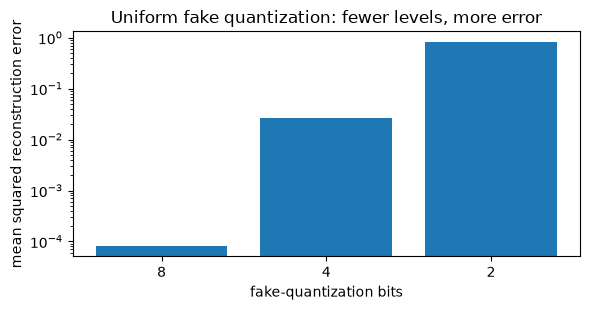

In [6]:
plt.figure(figsize=(6, 3.2))
plt.bar(
    [str(row['bits']) for row in quantization_results],
    [row['mse'] for row in quantization_results],
)
plt.yscale('log')
plt.xlabel('fake-quantization bits')
plt.ylabel('mean squared reconstruction error')
plt.title('Uniform fake quantization: fewer levels, more error')
plt.tight_layout()
plt.show()

In [7]:
def weight_floor_gib(parameters_billions: float, bits_per_weight: float) -> float:
    return parameters_billions * 1e9 * bits_per_weight / 8 / 1024**3

memory_ledger = []
for parameters_billions in (1, 3, 7):
    fp16_weights = weight_floor_gib(parameters_billions, 16)
    four_bit_weights = weight_floor_gib(parameters_billions, 4)
    memory_ledger.append({
        'parameters_billions': parameters_billions,
        'fp16_weight_floor_gib': round(fp16_weights, 2),
        'four_bit_weight_floor_gib': round(four_bit_weights, 2),
        'rough_qlora_total_before_activations_gib': round(four_bit_weights * 1.8, 2),
    })
memory_ledger

[{'parameters_billions': 1,
  'fp16_weight_floor_gib': 1.86,
  'four_bit_weight_floor_gib': 0.47,
  'rough_qlora_total_before_activations_gib': 0.84},
 {'parameters_billions': 3,
  'fp16_weight_floor_gib': 5.59,
  'four_bit_weight_floor_gib': 1.4,
  'rough_qlora_total_before_activations_gib': 2.51},
 {'parameters_billions': 7,
  'fp16_weight_floor_gib': 13.04,
  'four_bit_weight_floor_gib': 3.26,
  'rough_qlora_total_before_activations_gib': 5.87}]

## Day 12 practice and acceptance

1. Derive the theoretical weight floor for a 7B model at 16, 8, and 4 bits.
2. Add rows for LoRA parameters, gradients, optimizer states, and activations.
3. Explain why NF4 cannot be faithfully represented by the uniform function above.
4. Predict which tensor categories change with sequence length and batch size.

**Accept the day when:** you label the fake-quantization demo honestly, distinguish a weight floor from peak training memory, and can explain what is frozen versus trainable in QLoRA.

# Day 13 — Hugging Face and PEFT preflight without downloads

Library usage should begin with an audit, not with a large download. Record the base model ID and revision, license, tokenizer, task formulation, target modules, rank, alpha, dropout, quantization settings, dtype, device map, seed, split, and save path.

The lightweight route below inventories the local model and writes an in-memory run manifest. The Optional Heavy route later installs Transformers, Datasets, PEFT, Accelerate, and a platform-compatible 4-bit backend.

In [8]:
optional_packages = ('transformers', 'datasets', 'peft', 'accelerate', 'bitsandbytes')
package_inventory = {
    package: importlib.util.find_spec(package) is not None for package in optional_packages
}
package_inventory

{'transformers': False,
 'datasets': False,
 'peft': False,
 'accelerate': False,
 'bitsandbytes': False}

In [9]:
audit_config = GPTConfig(vocab_size=32, block_size=16, dim=32, n_heads=4, n_layers=1)
audit_model = TinyGPT(audit_config)
linear_inventory = [
    {
        'name': name,
        'in_features': module.in_features,
        'out_features': module.out_features,
    }
    for name, module in audit_model.named_modules()
    if isinstance(module, nn.Linear)
]
run_manifest = {
    'route': 'Core Light local audit',
    'base_model': 'dl100h.TinyGPT (local teaching model)',
    'task': 'causal language modeling',
    'target_modules': ['blocks.0.attn.qkv', 'blocks.0.attn.proj'],
    'rank': 8,
    'alpha': 16,
    'dropout': 0.05,
    'bias': 'none',
    'quantization': 'none in Core Light; 4-bit is Optional Heavy',
    'seed': 13,
}
print(json.dumps(run_manifest, indent=2))
linear_inventory

{
  "route": "Core Light local audit",
  "base_model": "dl100h.TinyGPT (local teaching model)",
  "task": "causal language modeling",
  "target_modules": [
    "blocks.0.attn.qkv",
    "blocks.0.attn.proj"
  ],
  "rank": 8,
  "alpha": 16,
  "dropout": 0.05,
  "bias": "none",
  "quantization": "none in Core Light; 4-bit is Optional Heavy",
  "seed": 13
}


[{'name': 'blocks.0.attn.qkv', 'in_features': 32, 'out_features': 96},
 {'name': 'blocks.0.attn.proj', 'in_features': 32, 'out_features': 32},
 {'name': 'blocks.0.mlp.net.0', 'in_features': 32, 'out_features': 128},
 {'name': 'blocks.0.mlp.net.2', 'in_features': 128, 'out_features': 32},
 {'name': 'lm_head', 'in_features': 32, 'out_features': 32}]

In [10]:
qa_pairs = [
    ('Is dark tissue visible?', 'yes'),
    ('What shape is the region?', 'round'),
]
separator = ' -> '
collation_text = ''.join(question + separator + answer for question, answer in qa_pairs)
qa_tokenizer = CharTokenizer.from_text(collation_text)
encoded_examples = []
for question, answer in qa_pairs:
    prompt = question + separator
    full_text = prompt + answer
    ids = qa_tokenizer.encode(full_text)
    labels = [-100] * len(qa_tokenizer.encode(prompt)) + qa_tokenizer.encode(answer)
    encoded_examples.append((ids, labels))

maximum_length = max(len(ids) for ids, _ in encoded_examples)
batch_ids = torch.zeros(len(encoded_examples), maximum_length, dtype=torch.long)
batch_labels = torch.full_like(batch_ids, -100)
attention_mask = torch.zeros_like(batch_ids, dtype=torch.bool)
for row, (ids, labels) in enumerate(encoded_examples):
    length = len(ids)
    batch_ids[row, :length] = torch.tensor(ids)
    batch_labels[row, :length] = torch.tensor(labels)
    attention_mask[row, :length] = True

assert torch.all(batch_labels[~attention_mask] == -100)
{
    'input_shape': tuple(batch_ids.shape),
    'loss_positions': (batch_labels != -100).sum(dim=-1).tolist(),
    'valid_positions': attention_mask.sum(dim=-1).tolist(),
}

{'input_shape': (2, 34), 'loss_positions': [3, 5], 'valid_positions': [30, 34]}

## Day 13 practice and acceptance

1. Explain why module names must be inspected before choosing PEFT target modules.
2. Extend the manifest with package versions, model revision, license, dtype, and save path.
3. Decide whether the prompt tokens should contribute to loss for your chosen QA formulation.
4. Audit the external Week 3 reference notebook: record every model, dataset, dependency, and hidden hardware assumption before running it.

**Accept the day when:** the package inventory is explicit, target names exist in the audited architecture, the loss mask matches the task, and no download is required to explain the planned pipeline.

# Day 14 — QA metrics, baselines, strata, and leakage

Question answering can be formulated as answer classification, conditional generation, or extractive prediction. PathVQA commonly mixes yes/no and open answers, so aggregate scores can hide different behavior.

Exact Match compares normalized strings. Token F1 gives partial credit through token overlap. Both depend on the normalization contract, which must be fixed before comparing systems.

In [11]:
metric_examples = [
    ('The round cell.', 'round cell'),
    ('pink round tissue', 'round tissue'),
    ('yes', 'Yes!'),
    ('purple tissue', 'pink tissue'),
]
metric_rows = []
for prediction, target in metric_examples:
    metric_rows.append({
        'prediction': prediction,
        'target': target,
        'normalized_prediction': normalize_answer(prediction),
        'normalized_target': normalize_answer(target),
        'exact_match': exact_match(prediction, target),
        'token_f1': round(token_f1(prediction, target), 3),
    })
metric_rows

[{'prediction': 'The round cell.',
  'target': 'round cell',
  'normalized_prediction': 'round cell',
  'normalized_target': 'round cell',
  'exact_match': 1.0,
  'token_f1': 1.0},
 {'prediction': 'pink round tissue',
  'target': 'round tissue',
  'normalized_prediction': 'pink round tissue',
  'normalized_target': 'round tissue',
  'exact_match': 0.0,
  'token_f1': 0.8},
 {'prediction': 'yes',
  'target': 'Yes!',
  'normalized_prediction': 'yes',
  'normalized_target': 'yes',
  'exact_match': 1.0,
  'token_f1': 1.0},
 {'prediction': 'purple tissue',
  'target': 'pink tissue',
  'normalized_prediction': 'purple tissue',
  'normalized_target': 'pink tissue',
  'exact_match': 0.0,
  'token_f1': 0.5}]

In [12]:
type_counts = Counter(example['type'] for example in TOY_PATHVQA)
answer_counts_by_type = {
    question_type: Counter(
        example['answer'] for example in TOY_PATHVQA if example['type'] == question_type
    )
    for question_type in type_counts
}
majority_baselines = {
    question_type: counts.most_common(1)[0] for question_type, counts in answer_counts_by_type.items()
}

train_questions = ['Is the tissue predominantly pink?', 'What shape is the highlighted region?']
validation_questions = ['Is tissue predominantly pink!', 'Are dark nuclei visible?']
normalized_train = {normalize_answer(question) for question in train_questions}
normalized_validation = {normalize_answer(question) for question in validation_questions}
leaked_questions = normalized_train & normalized_validation

{
    'type_counts': dict(type_counts),
    'majority_baselines': majority_baselines,
    'normalized_question_overlap': sorted(leaked_questions),
}

{'type_counts': {'yes/no': 2, 'open': 2},
 'majority_baselines': {'yes/no': ('yes', 2), 'open': ('round', 1)},
 'normalized_question_overlap': ['is tissue predominantly pink']}

## Day 14 practice and acceptance

1. Add empty-answer and repeated-token cases to the metric table.
2. Report metrics separately for yes/no and open questions.
3. Create a majority-answer baseline and compare it with a random baseline.
4. Check image IDs, patient IDs, normalized questions, and near-duplicate answers across splits.
5. Write three failure records containing question, target, prediction, metric, and suspected cause.

**Accept the day when:** normalization is documented, EM and token F1 differences are explained, results are stratified, and split leakage checks precede model comparison.

# Day 15 — A controlled LoRA rank comparison

Research question: **How does adapter rank affect approximation quality and trainable parameter count when the true task shift is low rank?**

The synthetic target update below has rank at most four. Before running, predict that rank 2 has structural approximation error, while rank 8 has enough capacity but uses more parameters. Both runs use the same frozen base, generated task, optimizer family, step budget, and separate train/validation samples.

The Core Light comparison uses ranks 2 and 8 with one seed. Ranks 2, 4, 8, 16, repeated seeds, plots with uncertainty, and language-model adaptation are Optional Heavy extensions.

In [13]:
seed_everything(15)
input_dim, output_dim, true_rank = 16, 12, 4
frozen_weight = torch.randn(output_dim, input_dim)
true_update = torch.randn(output_dim, true_rank) @ torch.randn(true_rank, input_dim)
train_features = torch.randn(256, input_dim)
validation_features = torch.randn(128, input_dim)
with torch.no_grad():
    train_targets = train_features @ (frozen_weight + true_update).T
    validation_targets = validation_features @ (frozen_weight + true_update).T

{
    'train_shape': tuple(train_features.shape),
    'validation_shape': tuple(validation_features.shape),
    'true_update_matrix_rank': int(torch.linalg.matrix_rank(true_update)),
}

{'train_shape': (256, 16),
 'validation_shape': (128, 16),
 'true_update_matrix_rank': 4}

In [14]:
def run_rank(rank: int, steps: int = 250) -> tuple[dict, LoRALinear]:
    torch.manual_seed(150 + rank)
    base = nn.Linear(input_dim, output_dim, bias=False)
    with torch.no_grad():
        base.weight.copy_(frozen_weight)
    model = LoRALinear(base, rank=rank, alpha=rank, dropout=0.0)
    optimizer = torch.optim.Adam(
        [parameter for parameter in model.parameters() if parameter.requires_grad], lr=0.06
    )
    start_time = time.perf_counter()
    for _ in range(steps):
        training_loss = F.mse_loss(model(train_features), train_targets)
        optimizer.zero_grad(set_to_none=True)
        training_loss.backward()
        optimizer.step()
    runtime_seconds = time.perf_counter() - start_time
    model.eval()
    with torch.inference_mode():
        validation_loss = F.mse_loss(model(validation_features), validation_targets)
    assert model.base.weight.grad is None
    result = {
        'rank': rank,
        'trainable_parameters': count_parameters(model, trainable_only=True),
        'training_mse': training_loss.item(),
        'validation_mse': validation_loss.item(),
        'runtime_seconds': runtime_seconds,
    }
    return result, model


In [15]:
rank_results = []
rank_models = {}
for rank in (2, 8):
    result, fitted_model = run_rank(rank)
    rank_results.append(result)
    rank_models[rank] = fitted_model

results_by_rank = {row['rank']: row for row in rank_results}
assert results_by_rank[8]['validation_mse'] < results_by_rank[2]['validation_mse']
rank_results

[{'rank': 2,
  'trainable_parameters': 56,
  'training_mse': 5.848476886749268,
  'validation_mse': 6.258021831512451,
  'runtime_seconds': 0.05968079999911424},
 {'rank': 8,
  'trainable_parameters': 224,
  'training_mse': 4.216231172904372e-05,
  'validation_mse': 5.662822877638973e-05,
  'runtime_seconds': 0.05557059999955527}]

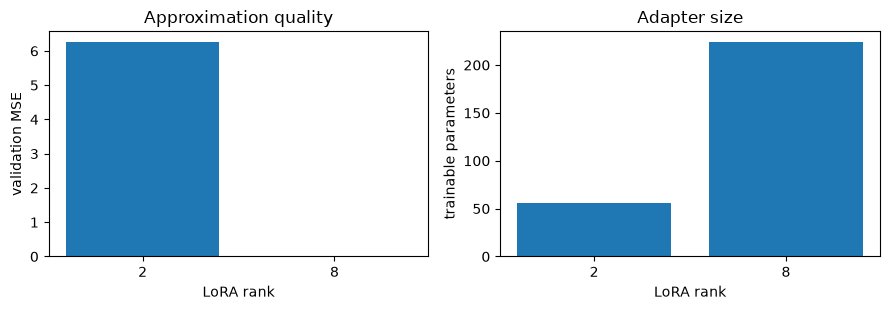

{'selected_rank': 8, 'merge_maximum_error': 5.7220458984375e-06}

In [16]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].bar([str(row['rank']) for row in rank_results], [row['validation_mse'] for row in rank_results])
axes[0].set(xlabel='LoRA rank', ylabel='validation MSE', title='Approximation quality')
axes[1].bar(
    [str(row['rank']) for row in rank_results],
    [row['trainable_parameters'] for row in rank_results],
)
axes[1].set(xlabel='LoRA rank', ylabel='trainable parameters', title='Adapter size')
figure.tight_layout()
plt.show()

best_rank = min(rank_results, key=lambda row: row['validation_mse'])['rank']
best_model = rank_models[best_rank]
merged_best_model = best_model.merged_linear().eval()
with torch.inference_mode():
    adapter_validation = best_model(validation_features)
    merged_validation = merged_best_model(validation_features)
torch.testing.assert_close(adapter_validation, merged_validation, rtol=1e-5, atol=1e-5)
{'selected_rank': best_rank, 'merge_maximum_error': (adapter_validation - merged_validation).abs().max().item()}

## Day 15 practice and acceptance

1. Add rank 4 and verify whether it is sufficient for the true rank-4 update.
2. Add rank 16 and discuss capacity versus trainable parameters.
3. Repeat at least three seeds and report mean and standard deviation.
4. Hold the optimization budget fixed, then separately compare a convergence-based stopping rule.
5. Record hypotheses before looking at results and explain any violation.

**Accept the day when:** train and validation samples are separate, controls are explicit, the base remains frozen, rank/quality/parameter trade-offs are reported, and single-seed limitations are stated.

# Week 3 acceptance checklist

- [ ] I can derive LoRA shapes, scaling, and trainable parameter counts.
- [ ] I can explain zero-$B$ initialization, first-step gradients, and adapter merging.
- [ ] I distinguish uniform fake quantization, NF4, and QLoRA training.
- [ ] My memory estimate separates weight storage from total peak memory.
- [ ] I can audit model module names before defining PEFT targets.
- [ ] I can write a reproducible adapter run manifest without downloading a model.
- [ ] I can compute normalized EM and token F1 and stratify QA results.
- [ ] I check split leakage before model comparison.
- [ ] I can interpret the controlled rank experiment and its single-seed limitation.

Save the memory ledger, package/module audit, metric table, rank results, and failure analysis in the experiment log. The Optional Heavy route should begin only after these lightweight checks are reproducible.